# 4. Resource Estimation Pipeline

In this tutorial, we demonstrate the full resource estimation pipeline using `quiche`. Furthermore, we perform a case study of when a certain simulation method is more advantageous than the others in terms of various metrics.

## 4.1. Hamiltonian simulation methods

We write the qubit Hamiltonian as a linear combination of Pauli strings, $H = \sum_{j=1}^{L} c_j P_j$, with one-norm $\lambda = \sum_j |c_j|$. QPE needs controlled applications of the time-evolution operator $e^{-iHt}$ (or a unitary with the same eigenvectors), and the three methods below build it in different ways.

- **Trotterisation** (`Simulation.Trotter`): Approximates $e^{-iHt}$ with a product of exponentials of the individual Pauli terms, $e^{-ic_jP_jt/r}$, repeated over $r$ time steps (a second-order product formula here). Each step costs about $L$ Pauli rotations, and the number of steps needed grows as $\epsilon^{-1/2}$, so the total cost scales as $\mathcal{O}(L\,\epsilon^{-1/2})$ rotations.

- **QDRIFT** (`Simulation.QDRIFT`): A randomised product formula that builds the evolution from $N$ Pauli rotations, sampling each term $P_j$ with probability $|c_j|/\lambda$. Each rotation is a single term, so the cost doesn't depend on $L$, but the number of samples grows as $\mathcal{O}(\lambda^2 t^2/\epsilon)$, which makes high precision expensive.

- **Qubitisation** (`Simulation.Qubitised`): Encodes $H/\lambda$ in a block of a larger unitary (a linear combination of unitaries (LCU) block encoding, built from PREPARE and SELECT oracles), then builds a quantum walk operator whose eigenphases are $\arccos(E_k/\lambda)$. There is no approximation error from splitting the exponential, and the cost is mostly Toffoli gates rather than arbitrary rotations. In exchange, it needs $\mathcal{O}(\log L)$ extra ancilla qubits, and each walk step costs $\mathcal{O}(L)$.

## 4.2. Setup

We fix the QPE method to be the textbook phase estimation method. Furthermore, we fix the fermion-to-qubit mapping to `Mapping.JordanWigner`. We vary the system size, i.e. `n_orb` with `n_elec = n_orb` for half filling, and the error budget.

The goal of this study is to answer which simulation method is cheapest, and what it costs in qubits for a given system size and target accuracy.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qualtran.surface_code import get_ccz2t_costs_from_grid_search
from random_hamiltonian import generate_random_sq_hamiltonian

from quiche import QPESpec
from quiche.core import Errors, Mapping, PhaseEstimation, Simulation
from quiche.resources.logical import (
    logical_gate_resources,
    logical_qubit_resources,
    logical_rotations_to_tgates,
)

# Fixed settings for the whole study.
QPE = PhaseEstimation.Textbook
MAPPING = Mapping.JordanWigner
SIMULATIONS = [Simulation.Trotter, Simulation.QDRIFT, Simulation.Qubitised]
SEED = 1

# Physical assumptions for the surface code cost model.
PHYS_ERR = 1e-3  # physical error rate per operation
CYCLE_TIME_US = 1.0  # surface code cycle time in microseconds
PHYS_ERROR_BUDGET = 1e-2  # allowed failure probability of the whole computation

# Use the same colour and marker for each method in every figure.
STYLE = {
    Simulation.Trotter.value: {"color": "tab:blue", "marker": "o"},
    Simulation.QDRIFT.value: {"color": "tab:orange", "marker": "s"},
    Simulation.Qubitised.value: {"color": "tab:green", "marker": "^"},
}

## 4.3. Metrics

For each calculation, we build the full QPE circuit as a Qualtran bloq with `QPESpec.get_composite_bloq()` and compute the following metrics.

**Logical metrics** (fault-tolerant gate counts, independent of the hardware):

- **Logical qubits**: the maximum number of logical qubits in use at any point of the circuit.
- **Toffoli count**: the number of Toffoli and AND gates. Qubitisation is built mostly from these.
- **T count**: the number of T gates, counting 4 T gates per Toffoli or AND gate. Trotterisation and QDRIFT are built almost entirely from arbitrary-angle $R_z$ rotations, which must first be synthesised into T gates. We use `logical_rotations_to_tgates`, which spends about $3\log_2(N_{\mathrm{rot}}/\epsilon_{\mathrm{rot}})$ T gates per rotation. Without this conversion, Trotterisation and QDRIFT would look artificially cheap.

**Physical metrics** (for surface code):

- **Physical qubits**: the number of physical qubits for the data block and the magic state factories.
- **Runtime**: the wall-clock time to run the algorithm once.
- **Spacetime volume**: physical qubits $\times$ runtime, in qubit-hours. A method can trade qubits for time, so this single number makes the methods easier to compare.

For the physical metrics, we use the CCZ $\to$ 2T factory model of [Gidney and Fowler (2019)](https://doi.org/10.22331/q-2019-04-30-135) as implemented in `qualtran.surface_code`. `get_ccz2t_costs_from_grid_search` searches over magic state factories and code distances and returns the layout with the smallest spacetime volume. It fails when no factory in its search space is good enough for the requested number of T gates, so we record those cases as missing data.

In [2]:
def get_physical_resources(gates, n_qubits):
    """Physical surface code costs, or NaNs if no valid layout exists."""
    try:
        cost, _, _ = get_ccz2t_costs_from_grid_search(
            n_logical_gates=gates,
            n_algo_qubits=n_qubits,
            phys_err=PHYS_ERR,
            error_budget=PHYS_ERROR_BUDGET,
            cycle_time_us=CYCLE_TIME_US,
        )
    except ValueError:
        # No magic state factory is reliable enough for this many T gates.
        return {
            "physical_qubits": np.nan,
            "runtime_hr": np.nan,
            "spacetime_qubit_hr": np.nan,
        }

    return {
        "physical_qubits": cost.footprint,
        "runtime_hr": cost.duration_hr,
        "spacetime_qubit_hr": cost.qubit_hours,
    }


def estimate_resources(ham, simulation, errors):
    """Logical and physical resource estimates for a single QPE calculation."""
    spec = QPESpec(
        hamiltonian=ham,
        state_prep=None,
        algorithm=QPE,
        simulation=simulation,
        error_budget=errors,
        seed=SEED,
    )
    bloq = spec.get_composite_bloq()

    # Logical resource estimates, with the rotations synthesised into T gates.
    gates = logical_gate_resources(bloq)
    gates_t = logical_rotations_to_tgates(gates, errors, rotation_synthesis="direct")
    n_qubits = logical_qubit_resources(bloq)

    return {
        "method": simulation.value,
        "num_terms": ham.paulis.num_words,
        "logical_qubits": n_qubits,
        "rotations": gates.rotation,
        "toffoli": gates_t.toffoli + gates_t.and_bloq,
        "t_count": gates_t.total_t_count(),
        **get_physical_resources(gates_t, n_qubits),
    }


def plot_metrics(df, x, xlabel, logx=False):
    """Plot the logical (top row) and physical (bottom row) metrics against x."""
    metrics = [
        ("logical_qubits", "Logical qubits"),
        ("toffoli", "Toffoli count"),
        ("t_count", "T count"),
        ("physical_qubits", "Physical qubits"),
        ("runtime_hr", "Runtime (hours)"),
        ("spacetime_qubit_hr", "Spacetime volume (qubit-hours)"),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
    for ax, (metric, label) in zip(axes.flat, metrics, strict=True):
        for simulation in SIMULATIONS:
            group = df[df["method"] == simulation.value]
            ax.plot(
                group[x],
                group[metric],
                label=simulation.value,
                **STYLE[simulation.value],
            )
        ax.set_ylabel(label)
        ax.set_yscale("log" if metric != "logical_qubits" else "linear")
        if logx:
            ax.set_xscale("log")
        ax.grid(True, which="major", alpha=0.3)
    for ax in axes[1]:
        ax.set_xlabel(xlabel)
    axes[0, 0].legend()
    fig.tight_layout()
    return fig, axes

## 4.4. Cost vs. system size

First, we fix the error budget and increase the number of spatial orbitals from 1 to 8 (2 to 16 qubits). The Hamiltonians are random, with dense one- and two-body integrals, so the number of Pauli terms $L$ grows roughly as $N^4$.

In [3]:
errors = Errors(
    estimation=1e-2, simulation=1e-3, rotations=1e-3, state_prep=1e-3, overlap=0.9
)

rows = []
for n_orb in range(1, 9):
    sq_ham = generate_random_sq_hamiltonian(n_orb=n_orb, n_elec=n_orb, seed=SEED)
    ham = sq_ham.to_qubit_hamiltonian(mapping=MAPPING)
    for simulation in SIMULATIONS:
        rows.append({"n_orb": n_orb, **estimate_resources(ham, simulation, errors)})

df_size = pd.DataFrame(rows)
df_size.set_index(["n_orb", "method"])

num_terms  logical_qubits    rotations   toffoli  \
n_orb method                                                        
1     trotter            3              15      8701920        66   
      qdrift             3              15    161674740        66   
      qubitised          3              43           45    145497   
2     trotter           24              17     69586380        66   
      qdrift            24              17    161674740        66   
      qubitised         24              55           45    594075   
3     trotter           99              19    287030880        66   
      qdrift            99              19    161674740        66   
      qubitised         99              61           45   1573063   
4     trotter          288              21    834991020        66   
      qdrift           288              21    161674740        66   
      qubitised        288              69           45   3502323   
5     trotter          675              23   1957004640        66   
      qdrift           675              23    161674740        66   
      qubitised        675              73           45  10062089   
6     trotter         1368              25   3966191820        66   
      qdrift          1368              25    161674740        66   
      qubitised       1368              77           45  12501279   
7     trotter         2499              27   7245254880        66   
      qdrift          2499              27    161674740        66   
      qubitised       2499              81           45  37599541   
8     trotter         4224              29  12246478380        66   
      qdrift          4224              29    161674740        66   
      qubitised       4224              85           45  40530251   

                       t_count  physical_qubits   runtime_hr  \
n_orb method                                                   
1     trotter        861490354         184510.0    27.220697   
      qdrift       17945896414         214894.0   567.040472   
      qubitised         584068         145330.0     0.006052   
2     trotter       7515329314         201364.0   237.463526   
      qdrift       17945896414         222452.0   567.040472   
      qubitised        2378380         175814.0     0.024556   
3     trotter      32721520594         248186.0  1152.070199   
      qdrift       17945896414         228218.0   567.040472   
      qubitised        6294332         208120.0     0.064940   
4     trotter      98528940634         261632.0  3469.039779   
      qdrift       17945896414         233984.0   567.040472   
      qubitised       14011372         224656.0     0.165932   
5     trotter     238754566354         307078.0  9268.319619   
      qdrift       17945896414         239750.0   567.040472   
      qubitised       40250436         257756.0     0.476610   
6     trotter     495773977774              NaN          NaN   
      qdrift       17945896414         245516.0   567.040472   
      qubitised       50007196         265256.0     0.592133   
7     trotter     927392624914              NaN          NaN   
      qdrift       17945896414         251282.0   567.040472   
      qubitised      150400244         285556.0     1.780814   
8     trotter    1592042189674              NaN          NaN   
      qdrift       17945896414         265240.0   567.040472   
      qubitised      162123084         306880.0     1.919616   

                 spacetime_qubit_hr  
n_orb method                         
1     trotter          5.022491e+06  
      qdrift           1.218536e+08  
      qubitised        8.796028e+02  
2     trotter          4.781661e+07  
      qdrift           1.261393e+08  
      qubitised        4.317340e+03  
3     trotter          2.859277e+08  
      qdrift           1.294088e+08  
      qubitised        1.351522e+04  
4     trotter          9.076118e+08  
      qdrift           1.326784e+08  
      qubitised        3.727765e+04  
5     trotter          2.

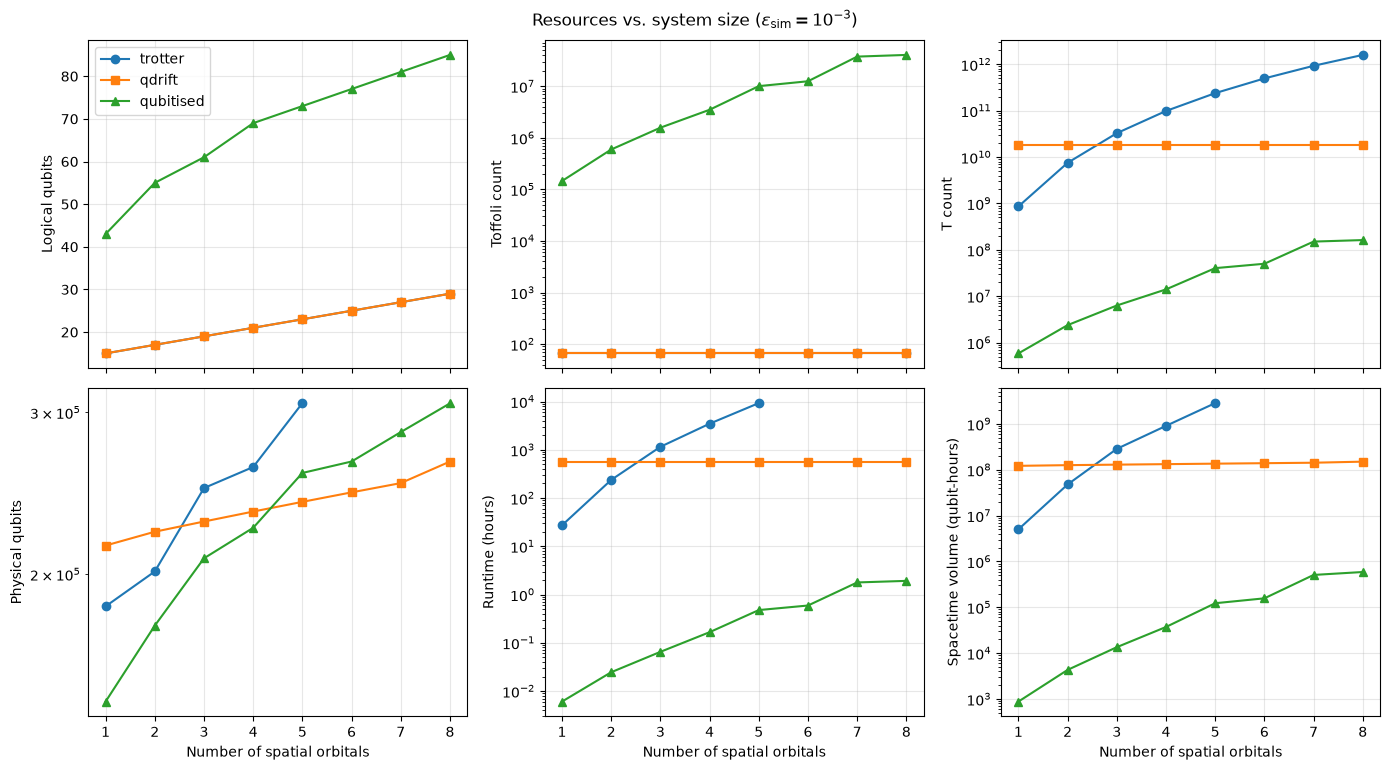

In [4]:
fig, axes = plot_metrics(df_size, x="n_orb", xlabel="Number of spatial orbitals")
fig.suptitle(r"Resources vs. system size ($\epsilon_{\mathrm{sim}} = 10^{-3}$)", y=1.02)
plt.show()

A few things to notice:

- **QDRIFT** has a constant T count of about $1.8\times10^{10}$ at every system size. The number of samples depends only on $\epsilon_{\mathrm{sim}}$, and each sample is a single rotation, however many terms the Hamiltonian has.
- **Trotterisation** costs about $L$ rotations per step, so its T count grows with the number of terms, from $8.6\times10^{8}$ to $1.6\times10^{12}$. It is cheaper than QDRIFT for the smallest systems, but QDRIFT is cheaper from `n_orb = 3` onwards. From `n_orb = 6`, no magic state factory in the search space can produce more than $5\times10^{11}$ T gates within the error budget, so the physical metrics are missing.
- **Qubitisation** needs 3 to 4 orders of magnitude fewer T gates than both product formulas, from $5.8\times10^{5}$ to $1.6\times10^{8}$. Its runtime stays below about 2 hours, while QDRIFT takes about 570 hours.
- The price of qubitisation is about $3\times$ more logical qubits (43 to 85, vs. 15 to 29) for the block encoding registers. The physical qubit counts are similar for all three methods, because the magic state factories dominate the physical footprint.
- Trotterisation and QDRIFT have the same logical qubit counts, so their lines overlap. Their Toffoli count of 66 comes from the inverse QFT, which all three methods share.

## 4.5. Cost vs. target accuracy

Next, we fix the system size at `n_orb = 3` and tighten the error budget. Each method spends its error budget differently:

- Trotterisation and QDRIFT use `simulation` to set the number of time steps or samples.
- Qubitisation has no simulation error, but uses `state_prep` to set the size of the register that stores the PREPARE rotation angles.

For a fair comparison, we set both `simulation` and `state_prep` to the same $\epsilon$ and keep the other entries of the budget fixed.

In [5]:
n_orb = 3
sq_ham = generate_random_sq_hamiltonian(n_orb=n_orb, n_elec=n_orb, seed=SEED)
ham = sq_ham.to_qubit_hamiltonian(mapping=MAPPING)

rows = []
for eps in np.logspace(-1, -6, 11):
    errors = Errors(
        estimation=1e-2, simulation=eps, rotations=1e-3, state_prep=eps, overlap=0.9
    )
    for simulation in SIMULATIONS:
        rows.append({"epsilon": eps, **estimate_resources(ham, simulation, errors)})

df_eps = pd.DataFrame(rows)
df_eps.set_index(["epsilon", "method"])

num_terms  logical_qubits     rotations  toffoli  \
epsilon  method                                                        
0.100000 trotter           99              19      29193300       66   
         qdrift            99              19       1625760       66   
         qubitised         99              49            45  1376455   
0.031623 trotter           99              19      51895980       66   
         qdrift            99              19       5122890       66   
         qubitised         99              51            45  1409223   
0.010000 trotter           99              19      90814860       66   
         qdrift            99              19      16171200       66   
         qubitised         99              55            45  1474759   
0.003162 trotter           99              19     162166140       66   
         qdrift            99              19      51134310       66   
         qubitised         99              59            45  1540295   
0.001000 trotter           99              19     287030880       66   
         qdrift            99              19     161674740       66   
         qubitised         99              61            45  1573063   
0.000316 trotter           99              19     509192820       66   
         qdrift            99              19     511232130       66   
         qubitised         99              65            45  1638599   
0.000100 trotter           99              19     903246480       66   
         qdrift            99              19    1616652810       66   
         qubitised         99              69            45  1704135   
0.000032 trotter           99              19    1607029560       66   
         qdrift            99              19    5112275850       66   
         qubitised         99              71            45  1736903   
0.000010 trotter           99              19    2855676960       66   
         qdrift            99              19   16166417130       66   
         qubitised         99              75            45  1802439   
0.000003 trotter           99              19    5078917980       66   
         qdrift            99              19   51122688480       66   
         qubitised         99              79            45  1867975   
0.000001 trotter           99              19    9030805920       66   
         qdrift            99              19  161664125850       66   
         qubitised         99              81            45  1900743   

                           t_count  physical_qubits    runtime_hr  \
epsilon  method                                                     
0.100000 trotter        3036103474         206410.0     95.932431   
         qdrift          147944434         162650.0      4.140385   
         qubitised         5507900         171412.0      0.056829   
0.031623 trotter        5500974154         206410.0    173.815498   
         qdrift          491797714         193258.0     15.539437   
         qubitised         5638972         180218.0      0.058181   
0.010000 trotter        9898820014         213578.0    312.775211   
         qdrift         1633291474         199754.0     51.607469   
         qubitised         5901116         186566.0      0.060885   
0.003162 trotter       18000441814         228218.0    568.763955   
         qdrift         5420237134         206410.0    171.264432   
         qubitised         6163260         199058.0      0.063588   
0.001000 trotter       32721520594         248186.0   1152.070199   
         qdrift        17945896414         228218.0    567.040472   
         qubitised         6294332         208120.0      0.064940   
0.000316 trotter       59066367394         248186.0   2079.628347   
         qdrift        59302927354         248186.0   2087.957229   
         qubitised         6556476         221252.0      0.067643   
0.000100 trotter      107486331394         255866.0   3784.414579   
         qdrift       195614990284         271482.

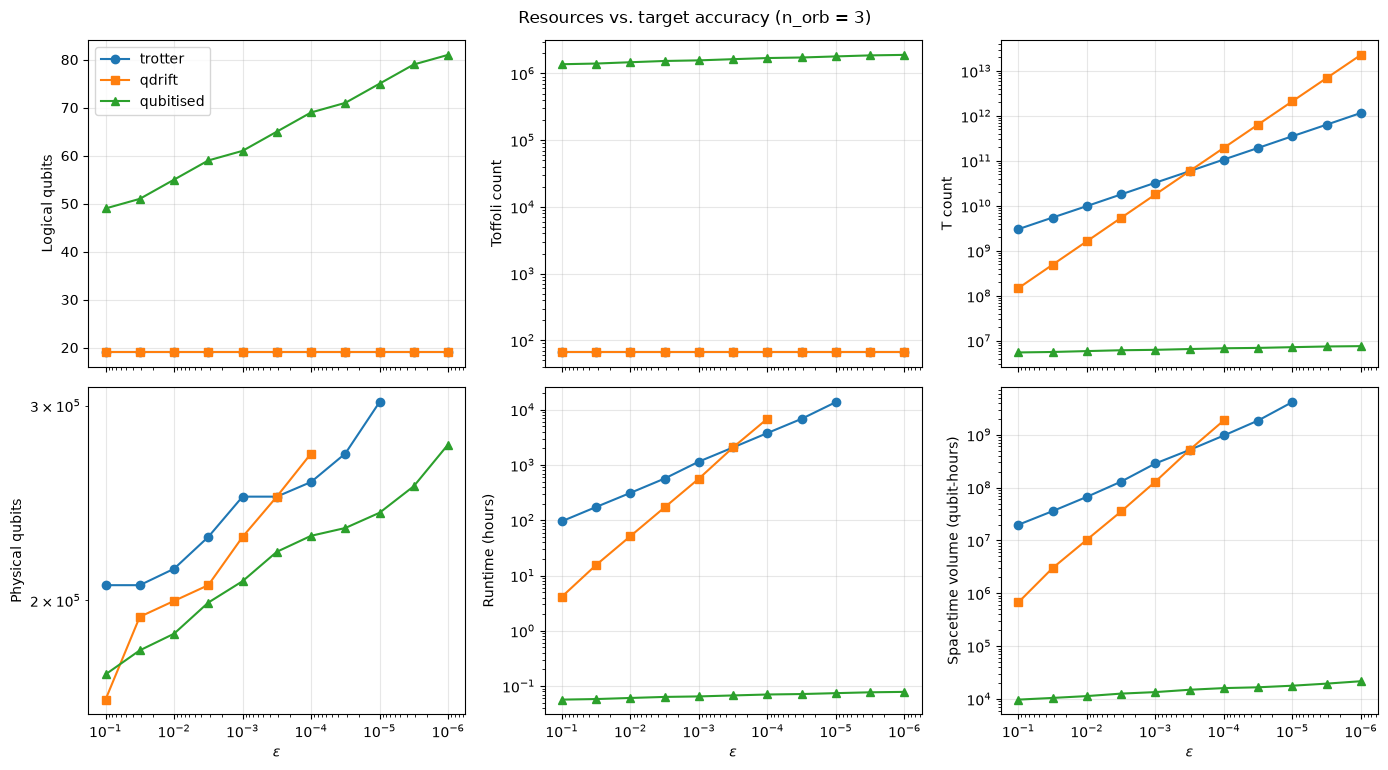

In [6]:
fig, axes = plot_metrics(df_eps, x="epsilon", xlabel=r"$\epsilon$", logx=True)
axes[0, 0].invert_xaxis()  # Higher accuracy to the right (shared by all panels).
fig.suptitle(f"Resources vs. target accuracy (n_orb = {n_orb})", y=1.02)
plt.show()

The slopes of the T count match the scalings from Section 4.1:

- **QDRIFT** grows as $\epsilon^{-1}$, from $1.5\times10^{8}$ to $2.3\times10^{13}$ over five decades of $\epsilon$.
- **Trotterisation** grows as $\epsilon^{-1/2}$, from $3.0\times10^{9}$ to $1.2\times10^{12}$.
- The two lines cross at around $\epsilon \approx 3\times10^{-4}$. QDRIFT is cheaper at low accuracy and Trotterisation is cheaper at high accuracy.
- **Qubitisation** is almost independent of $\epsilon$. Its T count grows by only about $40\%$, from $5.5\times10^{6}$ to $7.6\times10^{6}$, because a tighter budget only adds qubits to the PREPARE angle register, which grows as $\log(1/\epsilon)$. This shows up as the logical qubit count growing from 49 to 81.
- Below $\epsilon \approx 3\times10^{-5}$ (QDRIFT) and $10^{-5}$ (Trotterisation), the product formulas need too many T gates to fit the error budget, so their physical metrics are missing.

## 4.6. Takeaways

- **Qubitisation** is the cheapest method on every gate and time metric in this study, by several orders of magnitude, and the gap grows with both system size and accuracy. The price is about $3\times$ more logical qubits. In physical qubits the extra cost is small, because the magic state factories dominate the footprint.
- **QDRIFT** is the better product formula for large Hamiltonians at low accuracy, since its cost doesn't depend on the number of terms.
- **Trotterisation** is the better product formula for small Hamiltonians or high accuracy.

These results come with some caveats:

- The Trotter step count uses a bound in $\lambda^{p+1}$ instead of a commutator bound, so it is pessimistic.
- The product formula T counts are dominated by rotation synthesis. A cheaper synthesis method would narrow, but not close, the gap.
- The random Hamiltonians have dense integrals, so real molecules have fewer terms at the same size. A more compact block encoding, such as DF-THC, would make qubitisation cheaper still.